<a href="https://colab.research.google.com/github/mahmoud-elmowafy/california-housing-regression/blob/main/california_housing_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
data = fetch_california_housing(as_frame=True)

df = data.frame

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape: (20640, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [ ]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [ ]:
print("Number of Duplicates:", df.duplicated().sum())

Number of Duplicates: 0


In [ ]:
X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (20640, 8)
Target Shape: (20640,)


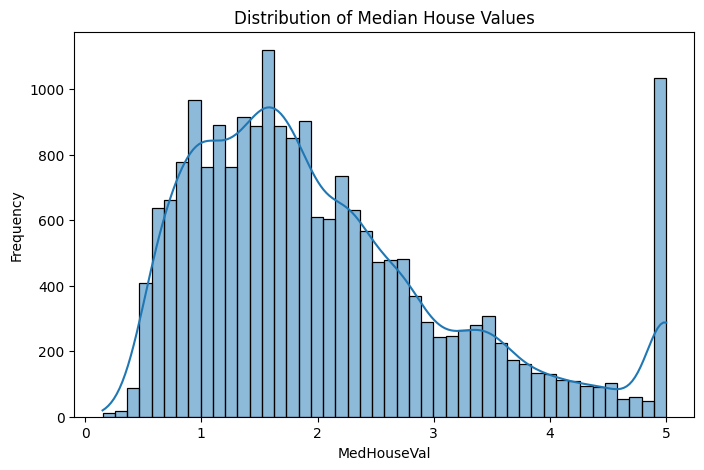

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(y, kde=True)
plt.title('Distribution of Median House Values')
plt.xlabel('MedHouseVal')
plt.ylabel('Frequency')
plt.show()

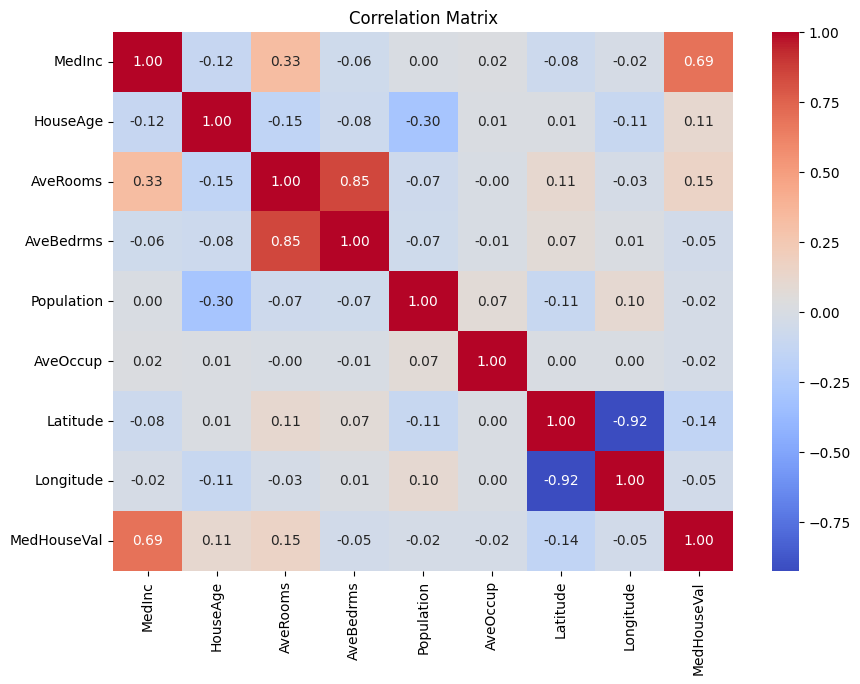

In [ ]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

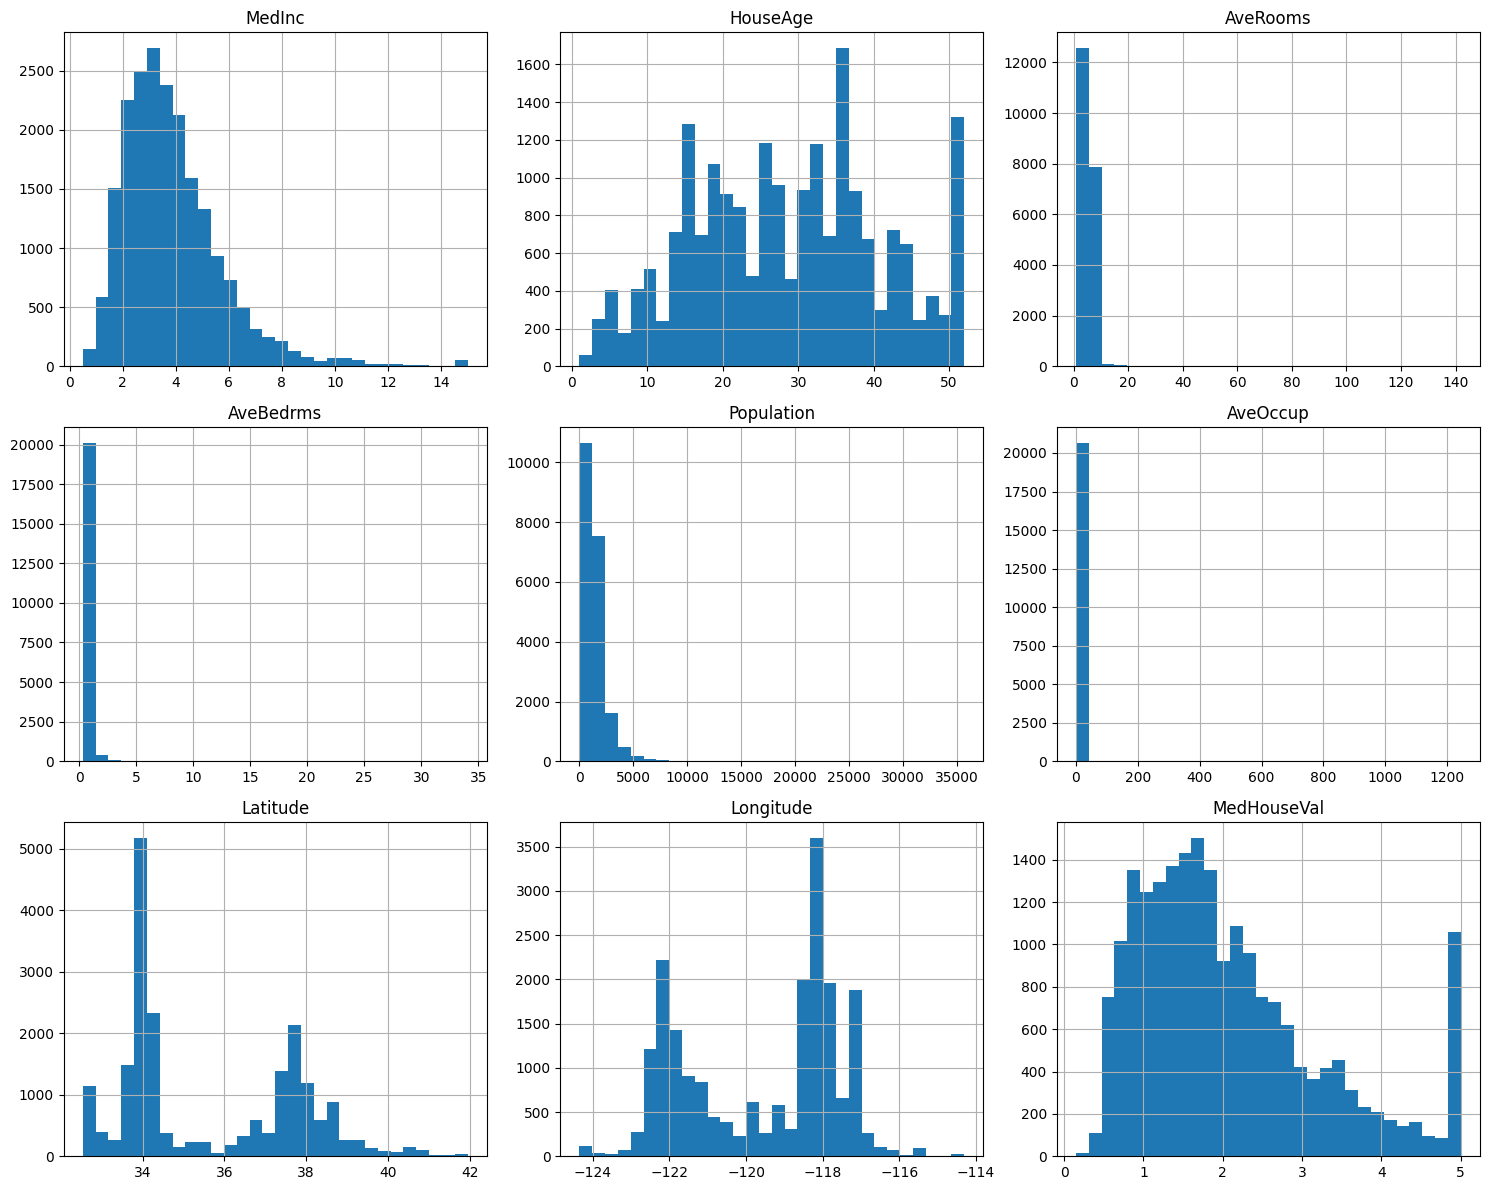

In [ ]:
df.hist(figsize=(15, 12), bins=30)
plt.tight_layout()
plt.show()

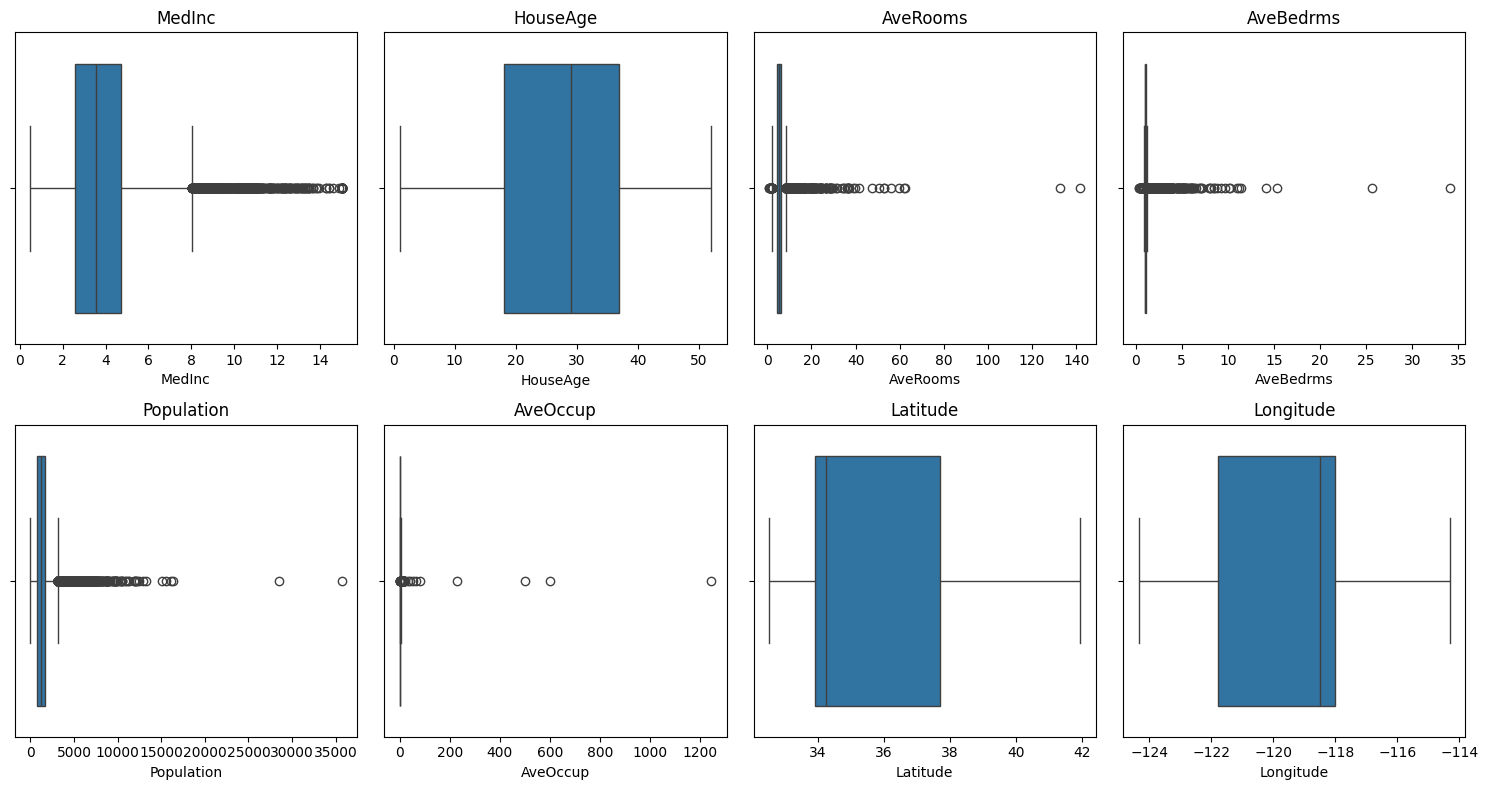

In [ ]:
plt.figure(figsize=(15, 8))

for i, col in enumerate(X.columns, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(x=X[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling Completed Successfully!")

Scaling Completed Successfully!


In [ ]:
lr_model = LinearRegression()

lr_model.fit(X_train_scaled, y_train)

LinearRegression()

In [ ]:
y_pred_lr = lr_model.predict(X_test_scaled)

In [ ]:
lr_mae = mean_absolute_error(y_test, y_pred_lr)
lr_mse = mean_squared_error(y_test, y_pred_lr)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("-------------------------")
print("MAE:", lr_mae)
print("MSE:", lr_mse)
print("RMSE:", lr_rmse)
print("R2 Score:", lr_r2)

Linear Regression Results
-------------------------
MAE: 0.5332001304956565
MSE: 0.5558915986952442
RMSE: 0.7455813830127763
R2 Score: 0.575787706032451


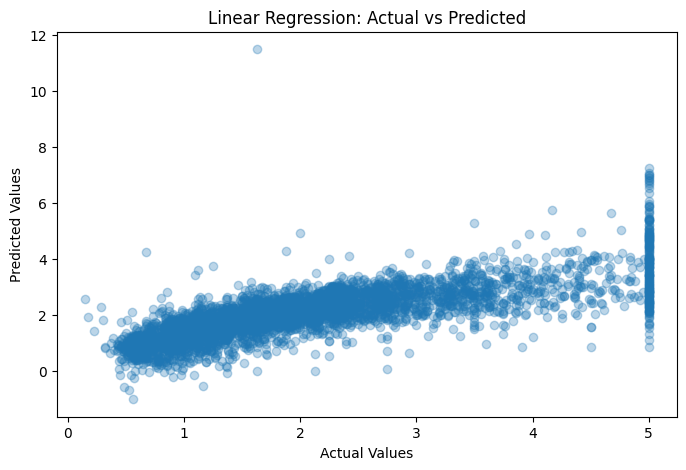

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_lr, alpha=0.3)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Linear Regression: Actual vs Predicted")

plt.show()

In [ ]:
svr_model = SVR(kernel='rbf')

svr_model.fit(X_train_scaled, y_train)

SVR()

In [ ]:
y_pred_svr = svr_model.predict(X_test_scaled)

In [ ]:
svr_mae = mean_absolute_error(y_test, y_pred_svr)
svr_mse = mean_squared_error(y_test, y_pred_svr)
svr_rmse = np.sqrt(svr_mse)
svr_r2 = r2_score(y_test, y_pred_svr)

print("SVR Results")
print("-------------------------")
print("MAE:", svr_mae)
print("MSE:", svr_mse)
print("RMSE:", svr_rmse)
print("R2 Score:", svr_r2)

SVR Results
-------------------------
MAE: 0.39859907695205365
MSE: 0.357004031933865
RMSE: 0.5974981438748282
R2 Score: 0.7275628923016773


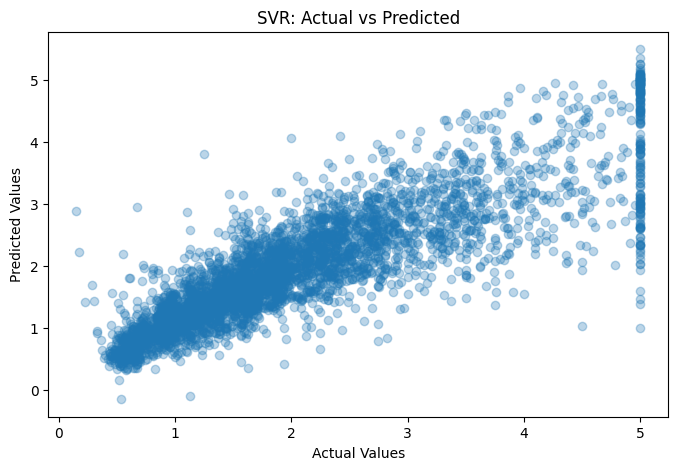

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_svr, alpha=0.3)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("SVR: Actual vs Predicted")

plt.show()

In [ ]:
knn_model = KNeighborsRegressor(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

KNeighborsRegressor()

In [ ]:
y_pred_knn = knn_model.predict(X_test_scaled)

In [ ]:
knn_mae = mean_absolute_error(y_test, y_pred_knn)
knn_mse = mean_squared_error(y_test, y_pred_knn)
knn_rmse = np.sqrt(knn_mse)
knn_r2 = r2_score(y_test, y_pred_knn)

print("KNN Results")
print("-------------------------")
print("MAE:", knn_mae)
print("MSE:", knn_mse)
print("RMSE:", knn_rmse)
print("R2 Score:", knn_r2)

KNN Results
-------------------------
MAE: 0.4461535271317829
MSE: 0.4324216146043236
RMSE: 0.6575877238850522
R2 Score: 0.6700101862970989


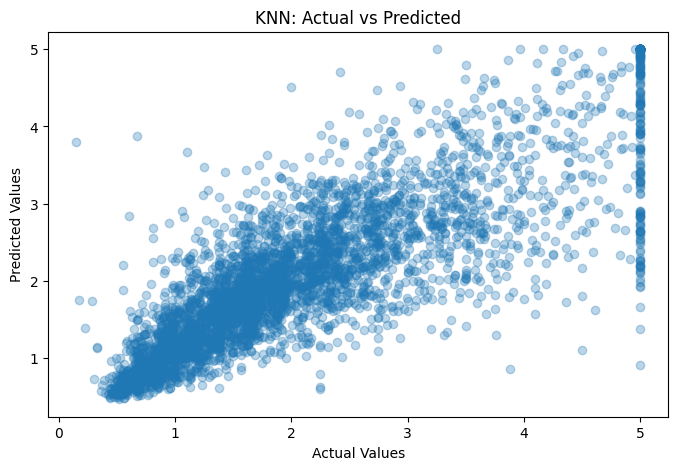

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_knn, alpha=0.3)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("KNN: Actual vs Predicted")

plt.show()


In [ ]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'SVR', 'KNN'],
    'MAE': [lr_mae, svr_mae, knn_mae],
    'MSE': [lr_mse, svr_mse, knn_mse],
    'RMSE': [lr_rmse, svr_rmse, knn_rmse],
    'R2 Score': [lr_r2, svr_r2, knn_r2]
})

results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.533200,0.555892,0.745581,0.575788
1,SVR,0.398599,0.357004,0.597498,0.727563
2,KNN,0.446154,0.432422,0.657588,0.670010
